# Benchmark de SAN en GPU: latencia y métricas complementarias

Evalúa **SAN** sobre CROHME 2014 y registra métricas de reconocimiento, latencia, tamaño del modelo y memoria GPU. Este notebook no importa ni ejecuta `torch.profiler` y no calcula FLOPs, por lo que el perfilado no puede afectar las muestras cronometradas.

La lectura de la imagen, el preprocesamiento en CPU, la decodificación y el cálculo de métricas quedan fuera del intervalo cronometrado.

In [1]:
from pathlib import Path
import gc, json, platform, sys, time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path.cwd() / '..', Path.cwd() / '../..']:
        candidate = candidate.resolve()
        if (candidate / 'SAN').is_dir() and (candidate / 'data').is_dir():
            return candidate
    raise FileNotFoundError('No se encontró la raíz con SAN/ y data/.')

ROOT = find_project_root()
SAN_ROOT = ROOT / 'SAN'
RESULTS_DIR = ROOT / 'Cascada' / '01_seleccion' / 'resultados'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda:0')
assert torch.cuda.is_available(), 'CUDA no está disponible.'
print('Raíz   :', ROOT)
print('GPU    :', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

Raíz   : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas
GPU    : NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch: 2.0.1+cu118


## Carga del modelo y del checkpoint

In [2]:
sys.path.insert(0, str(SAN_ROOT))
from utils import load_config
from infer.Backbone import Backbone
from dataset import Words

params = load_config(SAN_ROOT / '14.yaml')
params['device'] = DEVICE
params['word_path'] = str(SAN_ROOT / 'data' / 'word.txt')
params['checkpoint'] = str(SAN_ROOT / 'checkpoints' / 'SAN_decoder' / 'best.pth')
words = Words(params['word_path'])
params['word_num'], params['struct_num'], params['words'] = len(words), 7, words
model = Backbone(params)
state = torch.load(params['checkpoint'], map_location='cpu', weights_only=True)
model.load_state_dict(state['model'])
model = model.to(DEVICE).eval().requires_grad_(False)
torch.cuda.synchronize()
parameter_count = sum(p.numel() for p in model.parameters())
parameter_bytes = sum(p.numel() * p.element_size() for p in model.parameters())
buffer_bytes = sum(b.numel() * b.element_size() for b in model.buffers())
model_allocated_mib = torch.cuda.memory_allocated() / 1024**2
print('Checkpoint:', params['checkpoint'])
print(f'Parámetros: {parameter_count:,} ({parameter_count / 1e6:.3f} M)')
print(f'Pesos + buffers: {(parameter_bytes + buffer_bytes) / 1024**2:.2f} MiB')
print(f'VRAM asignada tras cargar: {model_allocated_mib:.2f} MiB')

try UTF-8 encoding
115 symbols in total
Checkpoint: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\SAN\checkpoints\SAN_decoder\best.pth
Parámetros: 7,996,103 (7.996 M)
Pesos + buffers: 30.55 MiB
VRAM asignada tras cargar: 30.70 MiB


c:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\.venv-hmer-gpu\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [3]:
def prediction_to_latex(prediction):
    if prediction is None or len(prediction) <= 1:
        return '<sin predicción>'
    children = {}
    for item in prediction:
        if len(item) < 4:
            continue
        try:
            node_id, parent_id = int(item[1]), int(item[2])
        except (TypeError, ValueError):
            continue
        children.setdefault(parent_id, []).append((node_id, str(item[3])))

    def walk(node_id):
        if node_id < 0 or node_id >= len(prediction):
            return ['<invalid>']
        symbol = str(prediction[node_id][0])
        kids = children.get(node_id, [])
        if not kids:
            return [symbol]
        result = [symbol]
        if symbol == r'\frac':
            for relation_name in ('Above', 'Below'):
                for child_id, relation in kids:
                    if relation == relation_name:
                        result += ['{'] + walk(child_id) + ['}']
            for child_id, relation in kids:
                if relation == 'Right':
                    result += walk(child_id)
            return result
        for child_id, relation in kids:
            if relation == 'l_sup':
                result += ['['] + walk(child_id) + [']']
        for child_id, relation in kids:
            if relation == 'Inside':
                result += ['{'] + walk(child_id) + ['}']
        for child_id, relation in kids:
            if relation in ('Sub', 'Below'):
                result += ['_', '{'] + walk(child_id) + ['}']
        for child_id, relation in kids:
            if relation in ('Sup', 'Above'):
                result += ['^', '{'] + walk(child_id) + ['}']
        for child_id, relation in kids:
            if relation == 'Right':
                result += walk(child_id)
        return result

    try:
        return ' '.join(walk(1))
    except Exception as exc:
        return f'<error SAN: {exc}>'

def prepare_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(path)
    tensor = torch.from_numpy(image).float().div_(255).unsqueeze(0).unsqueeze(0)
    mask = torch.ones_like(tensor)
    return tensor.to(DEVICE), mask.to(DEVICE), image.shape

def token_edit_distance(reference, prediction):
    previous = list(range(len(prediction) + 1))
    for row_index, reference_token in enumerate(reference, start=1):
        current = [row_index]
        for column_index, prediction_token in enumerate(prediction, start=1):
            insertion = current[column_index - 1] + 1
            deletion = previous[column_index] + 1
            substitution = previous[column_index - 1] + (reference_token != prediction_token)
            current.append(min(insertion, deletion, substitution))
        previous = current
    return previous[-1]

## Configuración y calentamiento

`MAX_SAMPLES = None` procesa toda la partición. El calentamiento no se incluye en los resultados.

In [4]:
YEAR = '2014'
MAX_SAMPLES = None
WARMUP_RUNS = 3
PROGRESS_EVERY = 25

split_dir = ROOT / 'data' / 'Modelo1' / YEAR
image_dir = split_dir / '14_test_images'
samples = []
for line in (split_dir / 'test_caption.txt').read_text(encoding='utf-8').splitlines():
    parts = line.strip().split()
    if parts:
        sample_id = parts[0][:-4] if parts[0].endswith('.jpg') else parts[0]
        samples.append((sample_id, ' '.join(parts[1:])))
if MAX_SAMPLES is not None:
    samples = samples[:MAX_SAMPLES]
if not samples:
    raise RuntimeError('No hay muestras para evaluar.')

print(f'Muestras seleccionadas: {len(samples)} | CROHME {YEAR}')
warm_image, warm_mask, _ = prepare_image(image_dir / f'{samples[0][0]}_0.bmp')
with torch.inference_mode():
    for _ in range(WARMUP_RUNS):
        warm_output = model(warm_image, warm_mask)
        torch.cuda.synchronize()
        del warm_output
del warm_image, warm_mask
gc.collect()
torch.cuda.synchronize()
print(f'Warm-up terminado: {WARMUP_RUNS} ejecuciones.')

Muestras seleccionadas: 986 | CROHME 2014
Warm-up terminado: 3 ejecuciones.


## Inferencia, latencia y métricas por expresión

Las sincronizaciones antes y después de `model(...)` garantizan que el cronómetro mida la ejecución GPU y no solo el lanzamiento asíncrono de los kernels. La decodificación, las métricas de reconocimiento y la consulta del pico de memoria se realizan fuera del intervalo cronometrado.

In [5]:
rows = []
for index, (sample_id, ground_truth) in enumerate(samples, start=1):
    path = image_dir / f'{sample_id}_0.bmp'
    row = {
        'index': index, 'sample_id': sample_id, 'image_file': path.name,
        'ground_truth': ground_truth, 'status': 'ok', 'error': '',
    }
    try:
        image, mask, (height, width) = prepare_image(path)
        row.update({'height': height, 'width': width})

        gc.collect()
        torch.cuda.synchronize()
        baseline = torch.cuda.memory_allocated()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.inference_mode():
            output = model(image, mask)
        torch.cuda.synchronize()
        elapsed_ms = (time.perf_counter() - start) * 1000.0

        peak = torch.cuda.max_memory_allocated()
        prediction = prediction_to_latex(output)
        ground_truth_tokens = ground_truth.strip().split()
        prediction_tokens = prediction.strip().split()
        edit_distance = token_edit_distance(ground_truth_tokens, prediction_tokens)
        cer = edit_distance / max(len(ground_truth_tokens), 1)
        row.update({
            'prediction': prediction,
            'correct': int(edit_distance == 0),
            'edit_distance': edit_distance,
            'edit_distance_le_1': int(edit_distance <= 1),
            'edit_distance_le_2': int(edit_distance <= 2),
            'ground_truth_token_count': len(ground_truth_tokens),
            'prediction_token_count': len(prediction_tokens),
            'cer': cer,
            'latency_ms': elapsed_ms,
            'base_mib': baseline / 1024**2,
            'peak_total_mib': peak / 1024**2,
            'peak_increment_mib': (peak - baseline) / 1024**2,
        })
        del output, image, mask
    except Exception as exc:
        row.update({
            'status': 'error', 'error': f'{type(exc).__name__}: {exc}',
            'correct': np.nan, 'edit_distance': np.nan, 'cer': np.nan,
            'latency_ms': np.nan, 'peak_total_mib': np.nan, 'peak_increment_mib': np.nan,
        })
        if 'out of memory' in str(exc).lower():
            rows.append(row)
            raise
    rows.append(row)
    gc.collect()
    if index == 1 or index % PROGRESS_EVERY == 0 or index == len(samples):
        valid_now = [item['latency_ms'] for item in rows if item['status'] == 'ok']
        print(f'{index:4d}/{len(samples)} | válidas={len(valid_now):4d} | latencia media={np.mean(valid_now):.2f} ms')

   1/986 | válidas=   1 | latencia media=38.49 ms
  25/986 | válidas=  25 | latencia media=119.56 ms
  50/986 | válidas=  50 | latencia media=115.04 ms
  75/986 | válidas=  75 | latencia media=112.55 ms
 100/986 | válidas= 100 | latencia media=112.71 ms
 125/986 | válidas= 125 | latencia media=112.12 ms
 150/986 | válidas= 150 | latencia media=111.06 ms
 175/986 | válidas= 175 | latencia media=109.65 ms
 200/986 | válidas= 200 | latencia media=108.81 ms
 225/986 | válidas= 225 | latencia media=106.05 ms
 250/986 | válidas= 250 | latencia media=103.47 ms
 275/986 | válidas= 275 | latencia media=101.47 ms
 300/986 | válidas= 300 | latencia media=99.89 ms
 325/986 | válidas= 325 | latencia media=98.76 ms
 350/986 | válidas= 350 | latencia media=98.66 ms
 375/986 | válidas= 375 | latencia media=98.77 ms
 400/986 | válidas= 400 | latencia media=99.19 ms
 425/986 | válidas= 425 | latencia media=98.87 ms
 450/986 | válidas= 450 | latencia media=98.88 ms
 475/986 | válidas= 475 | latencia medi

## Resumen completo y visualización de latencia

,valor
model,SAN
measurement,"Recognition, GPU inference latency, model size..."
dataset,CROHME 2014
samples_requested,986
samples_valid,986
errors,0
exact_match_count,558
exact_match_percent,56.592292
edit_distance_le_1_count,729
edit_distance_le_1_percent,73.935091


CSV    : C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\benchmark_san_latencia_crohme_2014.csv
Resumen: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\resumen_san_latencia_crohme_2014.json


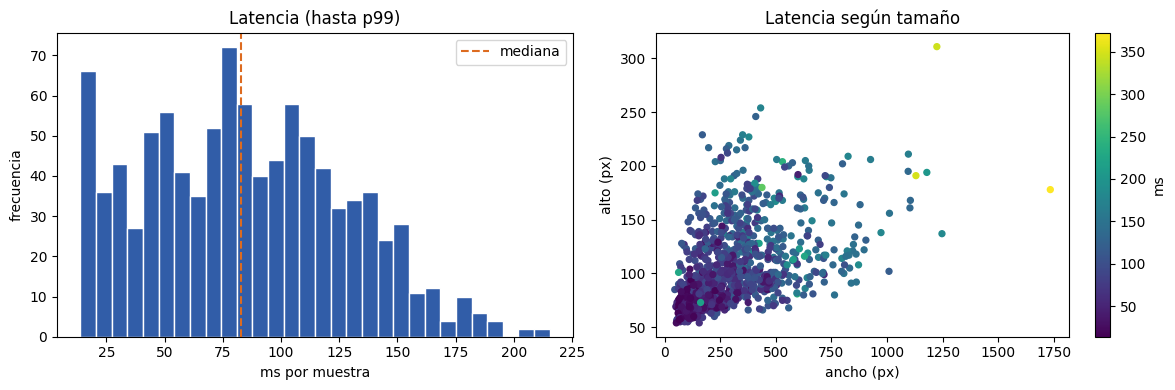

Gráfica: C:\Users\novac\Documents\Unidad\Documentos\IPN\Trabajo_terminal\Programas\Cascada\01_seleccion\resultados\benchmark_san_latencia_crohme_2014.png


In [6]:
results = pd.DataFrame(rows)
valid = results.loc[results['status'] == 'ok'].copy()
if valid.empty:
    raise RuntimeError('No hubo mediciones válidas.')
latencies = valid['latency_ms'].to_numpy(dtype=np.float64)
total_seconds = float(latencies.sum() / 1000.0)
total_edit_distance = int(valid['edit_distance'].sum())
total_reference_tokens = int(valid['ground_truth_token_count'].sum())
exact_match_count = int(valid['correct'].sum())
edit_distance_le_1_count = int(valid['edit_distance_le_1'].sum())
edit_distance_le_2_count = int(valid['edit_distance_le_2'].sum())
_, gpu_total_bytes = torch.cuda.mem_get_info()
summary = {
    'model': 'SAN',
    'measurement': 'Recognition, GPU inference latency, model size and VRAM; FLOPs excluded',
    'dataset': f'CROHME {YEAR}',
    'samples_requested': len(samples),
    'samples_valid': len(valid),
    'errors': int((results['status'] != 'ok').sum()),
    'exact_match_count': exact_match_count,
    'exact_match_percent': float(100 * exact_match_count / len(valid)),
    'edit_distance_le_1_count': edit_distance_le_1_count,
    'edit_distance_le_1_percent': float(100 * edit_distance_le_1_count / len(valid)),
    'edit_distance_le_2_count': edit_distance_le_2_count,
    'edit_distance_le_2_percent': float(100 * edit_distance_le_2_count / len(valid)),
    'cer_micro_percent': float(100 * total_edit_distance / total_reference_tokens),
    'cer_macro_percent': float(100 * valid['cer'].mean()),
    'total_edit_distance': total_edit_distance,
    'total_reference_tokens': total_reference_tokens,
    'cer_unit': 'tokens LaTeX separados por espacios',
    'latency_mean_ms': float(np.mean(latencies)),
    'latency_median_ms': float(np.median(latencies)),
    'latency_p95_ms': float(np.percentile(latencies, 95)),
    'latency_p99_ms': float(np.percentile(latencies, 99)),
    'latency_min_ms': float(np.min(latencies)),
    'latency_max_ms': float(np.max(latencies)),
    'total_inference_seconds': total_seconds,
    'total_inference_minutes': total_seconds / 60.0,
    'throughput_images_per_second': len(valid) / total_seconds,
    'parameters': parameter_count,
    'parameters_millions': parameter_count / 1e6,
    'weights_buffers_mib': (parameter_bytes + buffer_bytes) / 1024**2,
    'model_allocated_mib': model_allocated_mib,
    'max_peak_total_mib': float(valid['peak_total_mib'].max()),
    'max_peak_increment_mib': float(valid['peak_increment_mib'].max()),
    'images_resized': 0,
    'gpu': torch.cuda.get_device_name(0),
    'gpu_total_mib': gpu_total_bytes / 1024**2,
    'python': platform.python_version(),
    'pytorch': torch.__version__,
    'cuda': torch.version.cuda,
    'warmup_runs': WARMUP_RUNS,
    'timing_scope': 'Solo model(image, mask) en GPU; excluye lectura, preprocesamiento, decodificación, métricas y escritura.',
}

csv_path = RESULTS_DIR / f'benchmark_san_latencia_crohme_{YEAR}.csv'
json_path = RESULTS_DIR / f'resumen_san_latencia_crohme_{YEAR}.json'
results.to_csv(csv_path, index=False, encoding='utf-8')
json_path.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([summary]).T.rename(columns={0: 'valor'}))
print('CSV    :', csv_path)
print('Resumen:', json_path)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
display_limit = np.percentile(latencies, 99)
axes[0].hist(valid.loc[valid['latency_ms'] <= display_limit, 'latency_ms'], bins=30, color='#315da8', edgecolor='white')
axes[0].axvline(summary['latency_median_ms'], color='#dd6b20', linestyle='--', label='mediana')
axes[0].set(title='Latencia (hasta p99)', xlabel='ms por muestra', ylabel='frecuencia')
axes[0].legend()
scatter = axes[1].scatter(valid['width'], valid['height'], c=valid['latency_ms'], cmap='viridis', s=18)
axes[1].set(title='Latencia según tamaño', xlabel='ancho (px)', ylabel='alto (px)')
fig.colorbar(scatter, ax=axes[1], label='ms')
fig.tight_layout()
plot_path = RESULTS_DIR / f'benchmark_san_latencia_crohme_{YEAR}.png'
fig.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()
print('Gráfica:', plot_path)

## Lectura de los resultados

- Exact match y las tasas ≤1/≤2 usan distancia de Levenshtein sobre tokens LaTeX separados por espacios.
- CER micro agrega la distancia de edición y los tokens de todo el conjunto; CER macro promedia el CER de cada expresión.
- Cada muestra produce una única inferencia cronometrada después del calentamiento.
- La latencia incluye la ejecución completa de `model(image, mask)`; excluye lectura, preprocesamiento, decodificación y cálculo de métricas.
- El pico incremental de VRAM resta la memoria asignada inmediatamente antes de la inferencia. SAN usa el tamaño nativo de las imágenes, por lo que registra cero redimensionamientos.
- No se calculan FLOPs ni se inicia `torch.profiler`. Para evitar cualquier efecto residual, ejecute este notebook en una sesión limpia y no ejecute antes el notebook de FLOPs en el mismo kernel.